# Machine Learning Assignment 2

Work through the logistic regression example first. Then implement the other four classifiers, record your own results, and use the app and submission checklists below.

**Practice goal.** Predict the digit shown in a handwritten image from its 64 pixel measurements. The target column is `digit`, with values from 0 to 9.

| What the assignment requires | What this notebook uses |
| --- | --- |
| Public classification data | UCI Optical Recognition of Handwritten Digits |
| At least 500 instances | 1,797 images in the bundled UCI subset |
| At least 12 input features | 64 numeric features from an 8 × 8 grid |
| A classification target | 10 classes, the digits 0 through 9 |

Scikit-learn bundles the 1,797 rows from UCI's original test partition. For this practice run, we split those bundled rows into a new training set and a new holdout. Report the subset and split explicitly if you use them. [UCI dataset](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits) · [scikit-learn loader](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)

Open this notebook in BITS Virtual Lab and run the cells in order. The example uses `numpy`, `pandas`, `scikit-learn`, `joblib`, and `matplotlib`. If a package is missing, install it with `%pip install` followed by the package name in a notebook cell, then restart the kernel. The package for `sklearn` imports is `scikit-learn`.

## 1. Load and split the data

Flatten each image into a row of 64 features. The first feature is `pixel_0_0`, the last is `pixel_7_7`, and `digit` stays separate. Use one stratified 75/25 split for all five models so the test rows and class proportions are comparable. The seed 27 makes the split repeatable.

In [55]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
feature_columns = [
    f"pixel_{row}_{column}" for row in range(8) for column in range(8)
]
X = pd.DataFrame(digits.data.astype(int), columns=feature_columns)
y = pd.Series(digits.target, name="digit")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=27
)

print(f"{len(X_train):,} training rows and {len(X_test):,} test rows")
print(f"{X.shape[1]} features and {y.nunique()} classes")
pd.DataFrame({
    "Training": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index(),
})

1,347 training rows and 450 test rows
64 features and 10 classes


,Training,Test
digit,,
0,133,45
1,136,46
2,133,44
3,137,46
4,136,45
5,136,46
6,136,45
7,134,45
8,131,43


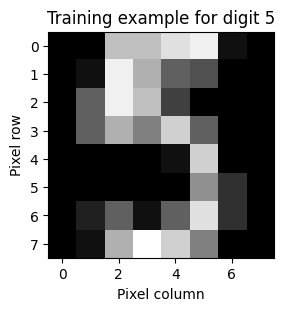

In [56]:
import matplotlib.pyplot as plt

pixels = X_train.iloc[0].to_numpy().reshape(8, 8)
fig, ax = plt.subplots(figsize=(3, 3), layout="constrained")
ax.imshow(pixels, cmap="gray", vmin=0, vmax=16, interpolation="nearest")
ax.set_title(f"Training example for digit {y_train.iloc[0]}")
ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")
plt.show()

## 2. Fit and evaluate one classifier

A pipeline keeps the scaler and classifier together. Its `fit` call learns the scaling parameters and model from the training rows. Predictions on the test set use those same scaling parameters. For later tuning, compare settings using cross-validation within the training partition and reserve the test partition for final evaluation.

| Metric | What to calculate |
| --- | --- |
| Accuracy | The fraction of correct predicted digits |
| AUC | For each digit, measure how well its probability ranks examples of that digit above all other digits. Average the 10 one-vs-rest AUC scores. |
| Precision | For each digit, find the fraction of predictions for that digit that are correct. Take the mean across digits. |
| Recall | For each digit, find the fraction of actual examples of that digit correctly identified. Take the mean across digits. |
| F1 | Compute the harmonic mean of precision and recall for each digit, then average the per-digit F1 scores. |
| MCC | Measure agreement between predicted and actual labels across the entire confusion matrix. Perfect agreement gives 1. |

Macro averaging gives each digit equal weight. Use predicted labels for the five hard-label metrics and class probabilities for AUC. The probability columns follow `model.classes_`. The example uses all ten labels for the macro scores and sets undefined per-class precision, recall, or F1 to zero. The scoring function returns `NaN` for AUC when the test file is missing a class. [Multiclass ROC AUC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html)

In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    matthews_corrcoef,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def evaluate_classifier(model, features, target):
    labels = model.classes_
    predictions = model.predict(features)
    precision, recall, f1, _ = precision_recall_fscore_support(
        target, predictions, labels=labels, average="macro", zero_division=0
    )
    auc = np.nan
    if set(target) == set(labels):
        auc = roc_auc_score(
            target, model.predict_proba(features), labels=labels,
            multi_class="ovr", average="macro"
        )
    scores = {
        "Accuracy": accuracy_score(target, predictions),
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "MCC": matthews_corrcoef(target, predictions),
    }
    matrix = pd.DataFrame(
        confusion_matrix(target, predictions, labels=labels),
        index=pd.Index(labels, name="Actual"),
        columns=pd.Index(labels, name="Predicted"),
    )
    return scores, matrix


baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
baseline.fit(X_train, y_train)
baseline_scores, baseline_matrix = evaluate_classifier(baseline, X_test, y_test)
pd.DataFrame([baseline_scores], index=["Logistic Regression"]).round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.98,0.9995,0.9802,0.98,0.98,0.9778


In [59]:
baseline_matrix

Predicted,0,1,2,3,4,5,6,7,8,9
Actual,,,,,,,,,,
0,45,0,0,0,0,0,0,0,0,0
1,0,45,0,0,0,0,0,0,1,0
2,0,0,44,0,0,0,0,0,0,0
3,0,0,0,45,0,1,0,0,0,0
4,0,0,0,0,44,0,0,0,0,1
5,0,0,0,0,0,44,1,0,0,1
6,0,0,0,0,0,0,45,0,0,0
7,0,0,0,0,0,0,0,44,1,0
8,0,2,0,0,0,0,0,0,41,0


**Check the result.** The reference run with scikit-learn 1.8.0 correctly classified 441 of 450 test rows, giving 0.9800 accuracy. The diagonal of the confusion matrix counts the correct predictions. Rows are actual digits and columns are predicted digits.

For digit 8, the reference matrix had 41 correct predictions, 43 actual examples and 44 predictions labelled 8. Its precision is 41/44 = 0.9318 and its recall is 41/43 = 0.9535. Locate the three off-diagonal predictions of 8 in the column. Then repeat the calculation for a different digit using your own matrix.

## 3. Implement the four remaining classifiers

Create one fitted estimator for each row below. Fit it with `X_train` and `y_train`, then call `evaluate_classifier(your_model, X_test, y_test)`. Use the same split, feature columns and metric definitions throughout.

| Model | Starting point | What to investigate in your run |
| --- | --- | --- |
| Decision Tree | Use `DecisionTreeClassifier` with a fixed seed. | How does limiting `max_depth` affect the gap between training and validation accuracy? |
| K-Nearest Neighbors | Put `StandardScaler` and `KNeighborsClassifier` in a pipeline. Start with five neighbors. | Which digits are often confused? Compare a second value of `n_neighbors` on training folds. |
| Gaussian Naive Bayes | Use `GaussianNB` on the original features. | Does it rank digit probabilities well even when it chooses the wrong top digit? Compare AUC with macro F1. |
| Support Vector Machine | Put `StandardScaler` and an RBF `SVC` in a pipeline. Wrap it in `CalibratedClassifierCV` with sigmoid calibration and five folds to get class probabilities. | Which errors does the SVM make on the same holdout? Compare MCC and AUC with the logistic baseline. |

Fit the SVM calibration on the training partition. [Probability calibration documentation](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibratedClassifierCV.html)

In [62]:
comparison = pd.DataFrame(
    index=[
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Naive Bayes",
        "Support Vector Machine",
    ],
    columns=list(baseline_scores),
    dtype=float,
)
comparison.loc["Logistic Regression"] = pd.Series(baseline_scores)

# Add your four fitted estimators and use their scores to fill the open rows.
comparison.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.98,0.9995,0.9802,0.98,0.98,0.9778
Decision Tree,NaN,NaN,NaN,NaN,NaN,NaN
KNN,NaN,NaN,NaN,NaN,NaN,NaN
Naive Bayes,NaN,NaN,NaN,NaN,NaN,NaN
Support Vector Machine,NaN,NaN,NaN,NaN,NaN,NaN


In [63]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=27)
tree.fit(X_train, y_train)

tree_scores, tree_matrix = evaluate_classifier(tree, X_test, y_test)
comparison.loc["Decision Tree"] = pd.Series(tree_scores)
comparison.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9800,0.9995,0.9802,0.980,0.9800,0.9778
Decision Tree,0.8467,0.9145,0.8460,0.846,0.8455,0.8297
KNN,NaN,NaN,NaN,NaN,NaN,NaN
Naive Bayes,NaN,NaN,NaN,NaN,NaN,NaN
Support Vector Machine,NaN,NaN,NaN,NaN,NaN,NaN


In [64]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5),
)
knn.fit(X_train, y_train)

knn_scores, knn_matrix = evaluate_classifier(knn, X_test, y_test)
comparison.loc["KNN"] = pd.Series(knn_scores)
comparison.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9800,0.9995,0.9802,0.9800,0.9800,0.9778
Decision Tree,0.8467,0.9145,0.8460,0.8460,0.8455,0.8297
KNN,0.9756,0.9951,0.9769,0.9755,0.9758,0.9729
Naive Bayes,NaN,NaN,NaN,NaN,NaN,NaN
Support Vector Machine,NaN,NaN,NaN,NaN,NaN,NaN


In [65]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

gnb_scores, gnb_matrix = evaluate_classifier(gnb, X_test, y_test)
comparison.loc["Naive Bayes"] = pd.Series(gnb_scores)
comparison.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9800,0.9995,0.9802,0.9800,0.9800,0.9778
Decision Tree,0.8467,0.9145,0.8460,0.8460,0.8455,0.8297
KNN,0.9756,0.9951,0.9769,0.9755,0.9758,0.9729
Naive Bayes,0.8556,0.9796,0.8785,0.8547,0.8567,0.8416
Support Vector Machine,NaN,NaN,NaN,NaN,NaN,NaN


In [66]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm = CalibratedClassifierCV(
    estimator=make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    method="sigmoid",
    cv=5,
)
svm.fit(X_train, y_train)

svm_scores, svm_matrix = evaluate_classifier(svm, X_test, y_test)
comparison.loc["Support Vector Machine"] = pd.Series(svm_scores)
comparison.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9800,0.9995,0.9802,0.9800,0.9800,0.9778
Decision Tree,0.8467,0.9145,0.8460,0.8460,0.8455,0.8297
KNN,0.9756,0.9951,0.9769,0.9755,0.9758,0.9729
Naive Bayes,0.8556,0.9796,0.8785,0.8547,0.8567,0.8416
Support Vector Machine,0.9867,0.9978,0.9869,0.9869,0.9868,0.9852


**Write your observations after running the models.** For each classifier, identify a metric or an error pattern and explain what it tells you about performance on these digits. Choose the winner using a criterion you can justify, such as the highest MCC for overall agreement. If the highest AUC belongs to a different classifier, explain the difference between ranking the true class highly and choosing it as the final label.

## 4. Practise saving a model and test CSV

This cell saves and reloads the baseline pipeline and a labelled test file in a temporary folder. A matching confusion matrix and scores show that the saved pipeline and raw CSV reproduce the offline result. Repeat the pattern in your own training code to save all five fitted models in `model/` and the held-out rows in `test_data.csv`. Keep the original feature columns and the `digit` target in the CSV.

In [69]:
from pathlib import Path
import joblib

downloads = Path("/home/s2026ak05288/Downloads")
model_dir = downloads / "model"
model_dir.mkdir(parents=True, exist_ok=True)

models = {
    "logistic.joblib": baseline,
    "decision_tree.joblib": tree,
    "knn.joblib": knn,
    "naive_bayes.joblib": gnb,
    "svm.joblib": svm,
}

for filename, fitted_model in models.items():
    path = model_dir / filename
    joblib.dump(fitted_model, path)
    print("Saved", path)

csv_path = downloads / "test_data.csv"
X_test.assign(digit=y_test).to_csv(csv_path, index=False)
print("Saved", csv_path)

Saved /home/s2026ak05288/Downloads/model/logistic.joblib
Saved /home/s2026ak05288/Downloads/model/decision_tree.joblib
Saved /home/s2026ak05288/Downloads/model/knn.joblib
Saved /home/s2026ak05288/Downloads/model/naive_bayes.joblib
Saved /home/s2026ak05288/Downloads/model/svm.joblib
Saved /home/s2026ak05288/Downloads/test_data.csv


## 5. Build your Streamlit evaluation page

| Requirement | Implementation to write in `app.py` |
| --- | --- |
| CSV upload | Use `st.file_uploader` for a labelled test CSV. Check for rows, all 64 feature columns, finite numeric inputs, and valid `digit` labels. Use the training feature order when selecting columns. |
| Model dropdown | Use `st.selectbox` with the five display names. Map each selection to the corresponding saved model in your repository. |
| Evaluation metrics | Load the fitted model, call your evaluation function with the uploaded features and labels, and display all six metrics. If a digit is absent, display AUC as unavailable and give the reason. |
| Confusion matrix or classification report | Display a matrix with actual labels on the rows and predicted labels on the columns. |

Keep model fitting in your training script. In the app, use the saved model for inference and accept CSV files through the uploader. Load `.joblib` files from your own repository. Inside `app.py`, you can build paths from `Path(__file__).resolve().parent` so they resolve correctly in deployment. [scikit-learn model persistence](https://scikit-learn.org/stable/model_persistence.html)

Run `python -m streamlit run app.py` from the project folder. Upload your `test_data.csv`, switch through all five models, and check that each model's metrics match your offline results. Try a CSV with a missing target column and verify that the page explains the problem.

## 6. Prepare the repository and deploy

| Repository item | Contents |
| --- | --- |
| `app.py` | Streamlit page for evaluating saved classifiers |
| `train.py` or a training notebook | Code for loading the data, training, evaluating and saving the classifiers |
| `model/` | Five trained model files, including fitted preprocessing wherever needed |
| `test_data.csv` | Held-out features and the `digit` target column |
| `requirements.txt` | Packages your source uses, including Streamlit, pandas, NumPy, scikit-learn and joblib, with the versions you tested |
| `README.md` | Problem statement, dataset description, GitHub link, five-model metric table, one observation per model and your overall winner |

Keep the training and deployed Python and package versions aligned, especially for scikit-learn and its dependencies. [Streamlit dependency guide](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/app-dependencies)

1. Push your project to GitHub and confirm that the evaluator can open the repository.
2. Sign in to Streamlit Community Cloud with GitHub, choose **Create app**, and select your repository, branch and `app.py`. Choose your training Python version in **Advanced settings**, then deploy. [Community Cloud deployment guide](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy)
3. Open the deployed URL, upload your test CSV, and try the dropdown. Verify that the evaluation works with the access the evaluator will have.